In [1]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field
from typing import Literal
from laya.integrations import LayaRouter
from langchain_groq import ChatGroq

from dotenv import load_dotenv

load_dotenv()

True

In [2]:
class State(BaseModel):
    user_query: str = Field(description="The user's query")
    sentiment: Literal["positive", "negative", "neutral"] = Field(
        default="",
        description="One of: positive, negative, neutral"
    )
    email: str = Field(
        default="",
        description="The email message to be classified"
    )

In [3]:
classification_llm = LayaRouter(
    criteria={
        "positive": "The text expresses a favorable, happy, or satisfied sentiment.",
        "negative": "The text expresses an unfavorable, angry, sad, or dissatisfied sentiment.",
        "neutral": "The text is factual, balanced, or does not express a clear positive or negative sentiment.",
    },
    instructions="What is the sentiment of the user's message?",
    state_key="user_query",
)

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    max_tokens=200,
    temperature=0.1
)

In [4]:
def generate_sentiment(state: State):
    sentiment = classification_llm.invoke({"user_query": state.user_query})
    return { "sentiment": sentiment }

def route_sentiment(state: State):
    return state.sentiment

def generate_positive_email(state: State):
    prompt = f"""
Write a professional customer-service email based on this customer message:

Customer message:
{state.user_query}

The customer has expressed a positive sentiment.
Thank them for their feedback and maintain a warm, appreciative tone.
Keep the email concise and natural.
Do not invent any information that is not present in the customer message.
"""
    
    result = llm.invoke(prompt)
    return {"email": result.content}


def generate_negative_email(state: State):
    prompt = f"""
Write a professional customer-service email based on this customer message:

Customer message:
{state.user_query}

The customer has expressed a negative sentiment.
Acknowledge their frustration, apologize where appropriate, and provide a helpful and empathetic response.
Keep the email concise and natural.
Do not invent any information that is not present in the customer message.
"""
    
    result = llm.invoke(prompt)
    return {"email": result.content}


def generate_neutral_email(state: State):
    prompt = f"""
Write a professional customer-service email based on this customer message:

Customer message:
{state.user_query}

The customer has expressed a neutral sentiment.
Respond clearly and professionally to their message without adding unnecessary emotion.
Keep the email concise and natural.
Do not invent any information that is not present in the customer message.
"""
    
    result = llm.invoke(prompt)
    return {"email": result.content}

In [5]:
graph = StateGraph(State)

graph.add_node("generate_sentiment", generate_sentiment)
graph.add_node("generate_positive_email", generate_positive_email)
graph.add_node("generate_negative_email", generate_negative_email)
graph.add_node("generate_neutral_email", generate_neutral_email)

graph.add_edge(START, 'generate_sentiment')
graph.add_conditional_edges('generate_sentiment', route_sentiment, {
   "positive": "generate_positive_email",
   "negative": "generate_negative_email",
   "neutral": "generate_neutral_email",
})

graph.add_edge("generate_positive_email", END)
graph.add_edge("generate_negative_email", END)
graph.add_edge("generate_neutral_email", END)

workflow = graph.compile()

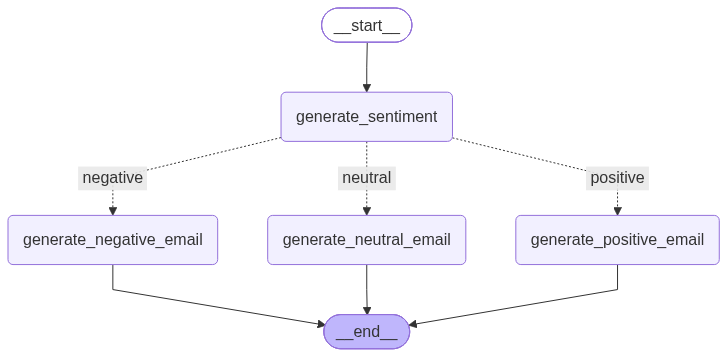

In [6]:
from IPython.display import Image,display
display(Image(workflow.get_graph().draw_mermaid_png()))

In [7]:
initial_state = {
    # "user_query": "I absolutely love this product! The quality is amazing.",
    "user_query": "This product is terrible. I'm extremely disappointed with it.",
}

result = workflow.invoke(initial_state)
print(result)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

/home/vikas/Coding_play_ground/AI/ai-engineering-learning/.venv/lib/python3.14/site-packages/laya/router.py:260: RuntimeWarning: laya: this checkpoint ships invalid temperatures or values outside [0.5, 5]; using choice:11+=0.10058280825614929 -> 0.5. Treat confidence from the affected entries as uncalibrated.
  agent = Agent(repo, device=self.device, token=self.token, subfolder=sub)


{'user_query': "This product is terrible. I'm extremely disappointed with it.", 'sentiment': 'negative', 'email': 'Subject: We’re Sorry to Hear About Your Experience  \n\nDear [Customer Name],\n\nThank you for reaching out and letting us know how disappointed you are with the product. I’m truly sorry that it did not meet your expectations.\n\nWe want to make this right for you. Could you please share a bit more detail about the issue you encountered? With that information we can explore the'}


In [ ]:
from IPython.display import Markdown,display

display(Markdown(f"Query: {result['user_query']}"))
display(Markdown(f"sentiment: {result['sentiment']}"))
display(Markdown(f"Email: {result['email']}"))

I absolutely love this product! The quality is amazing.

positive

Subject: Thank You for Your Kind Words!

Hi [Customer Name],

Thank you so much for sharing your enthusiasm about our product! We’re thrilled to hear that you love the quality and truly appreciate your positive feedback.

If there’s anything else we can help you with, please don’t hesitate to let us know.

Warm regards,  
[Your Name]  
Customer Service Team  
[Company Name]  
[Contact Information]